In [1]:
import os
if 'COLAB_GPU' in os.environ:
  print("GPU")
else:
  print("not GPU")

GPU


In [2]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


In [3]:
!pip install -q ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 109.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.8 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO
import os
import yaml
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key=...............)
project = rf.workspace("2tech").project("helmet-detection-zktr7")
version = project.version(5)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Helmet-Detection-5 in yolov8:: 100%|██████████| 1058/1058 [00:00<00:00, 4509.65it/s]


In [6]:
data_yaml = os.path.join(
    dataset.location,
    "data.yaml"
)

with open(data_yaml, "r") as file:
    data_config = yaml.safe_load(file)

print(data_config)
print("Classes:", data_config["names"])
print("Number of classes:", data_config["nc"])

{'names': ['helmet'], 'nc': 1, 'roboflow': {'license': 'CC BY 4.0', 'project': 'helmet-detection-zktr7', 'url': 'https://universe.roboflow.com/2tech/helmet-detection-zktr7/dataset/5', 'version': 5, 'workspace': '2tech'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}
Classes: ['helmet']
Number of classes: 1


In [7]:
model = YOLO("yolov8n.pt")

In [8]:
results = model.train(
    data=data_yaml,
    epochs=20,
    imgsz=640,
    batch=16,
    project="helmet-detection-zktr7",
    name="helmet-detection",
    patience=10,
    plots=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Helmet-Detection-5/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet-detection, nbs=64, nms=None, opset=None, opti

In [9]:
!ls "/content/runs/detect/helmet-detection-zktr7/helmet-detection/weights"

best.pt  last.pt


In [10]:
!ls "/content/runs/detect/helmet-detection-zktr7/helmet-detection/"

args.yaml			 results.csv	     val_batch0_labels.jpg
BoxF1_curve.png			 results.png	     val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg    val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg    val_batch1_pred.jpg
BoxR_curve.png			 train_batch220.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch221.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch222.jpg  weights
labels.jpg			 train_batch2.jpg


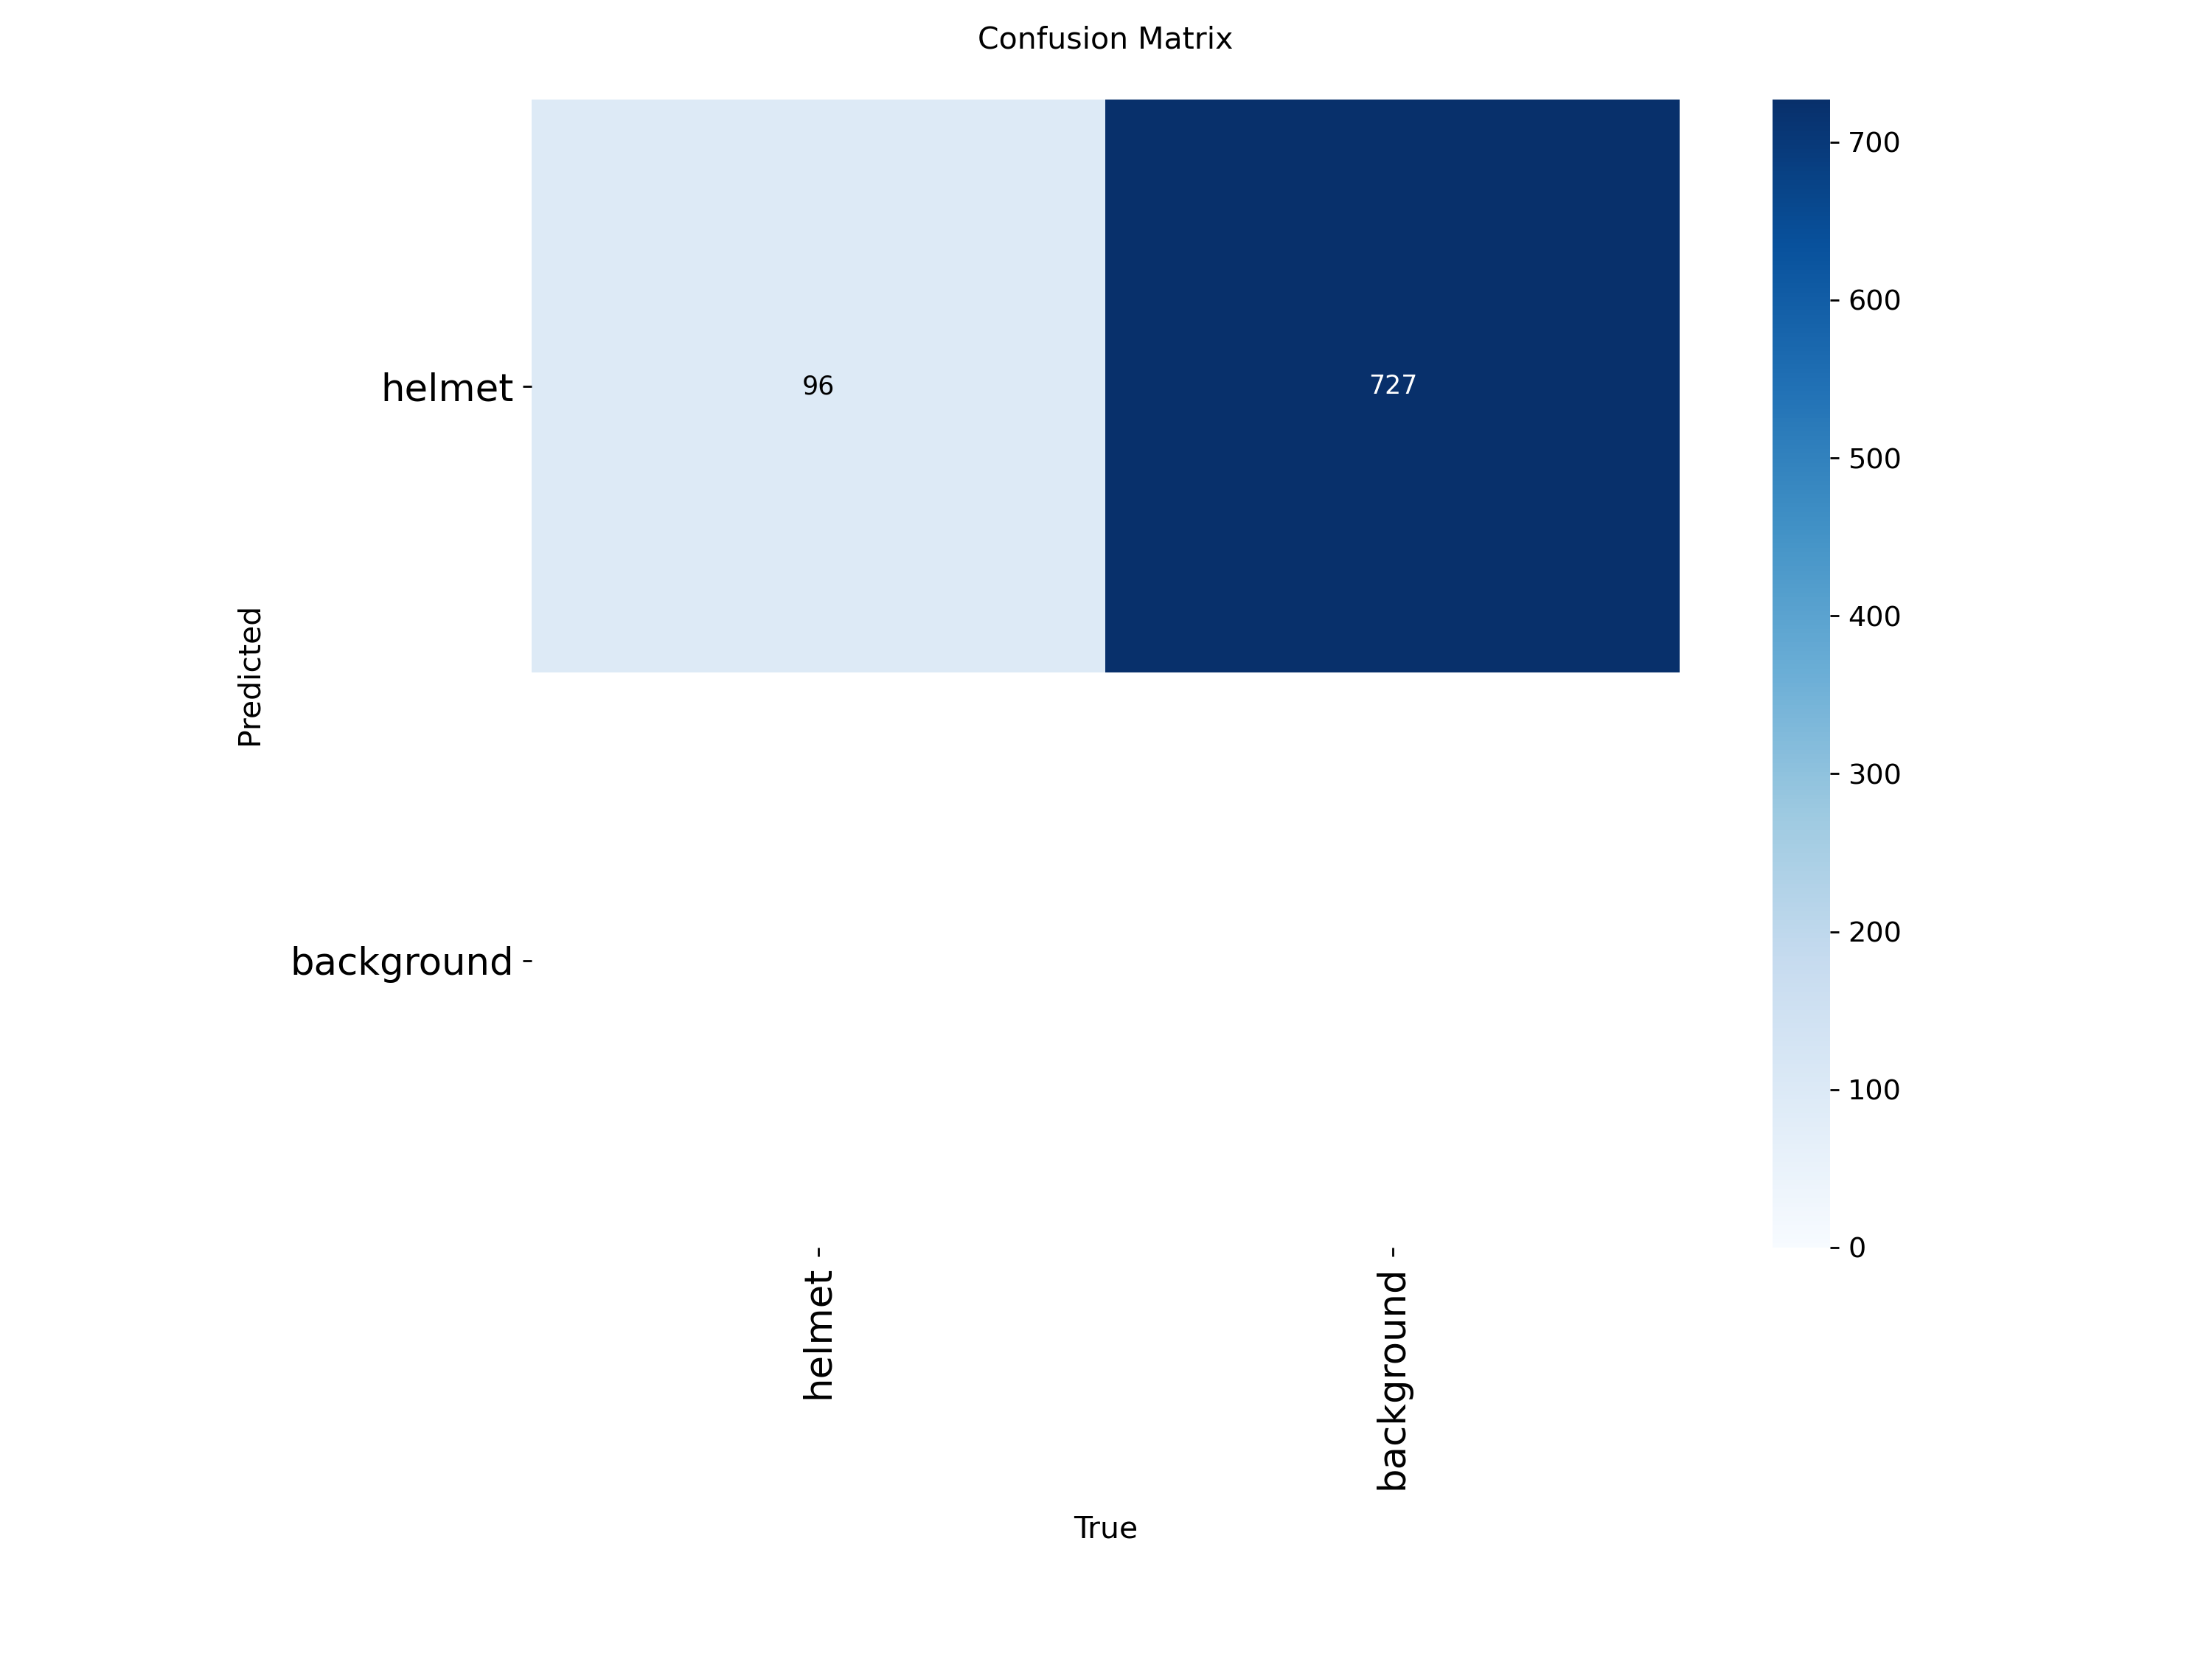

In [11]:
resultData = "/content/runs/detect/helmet-detection-zktr7/helmet-detection/"

from IPython.display import Image, display

Image(filename = f"{resultData}confusion_matrix.png")

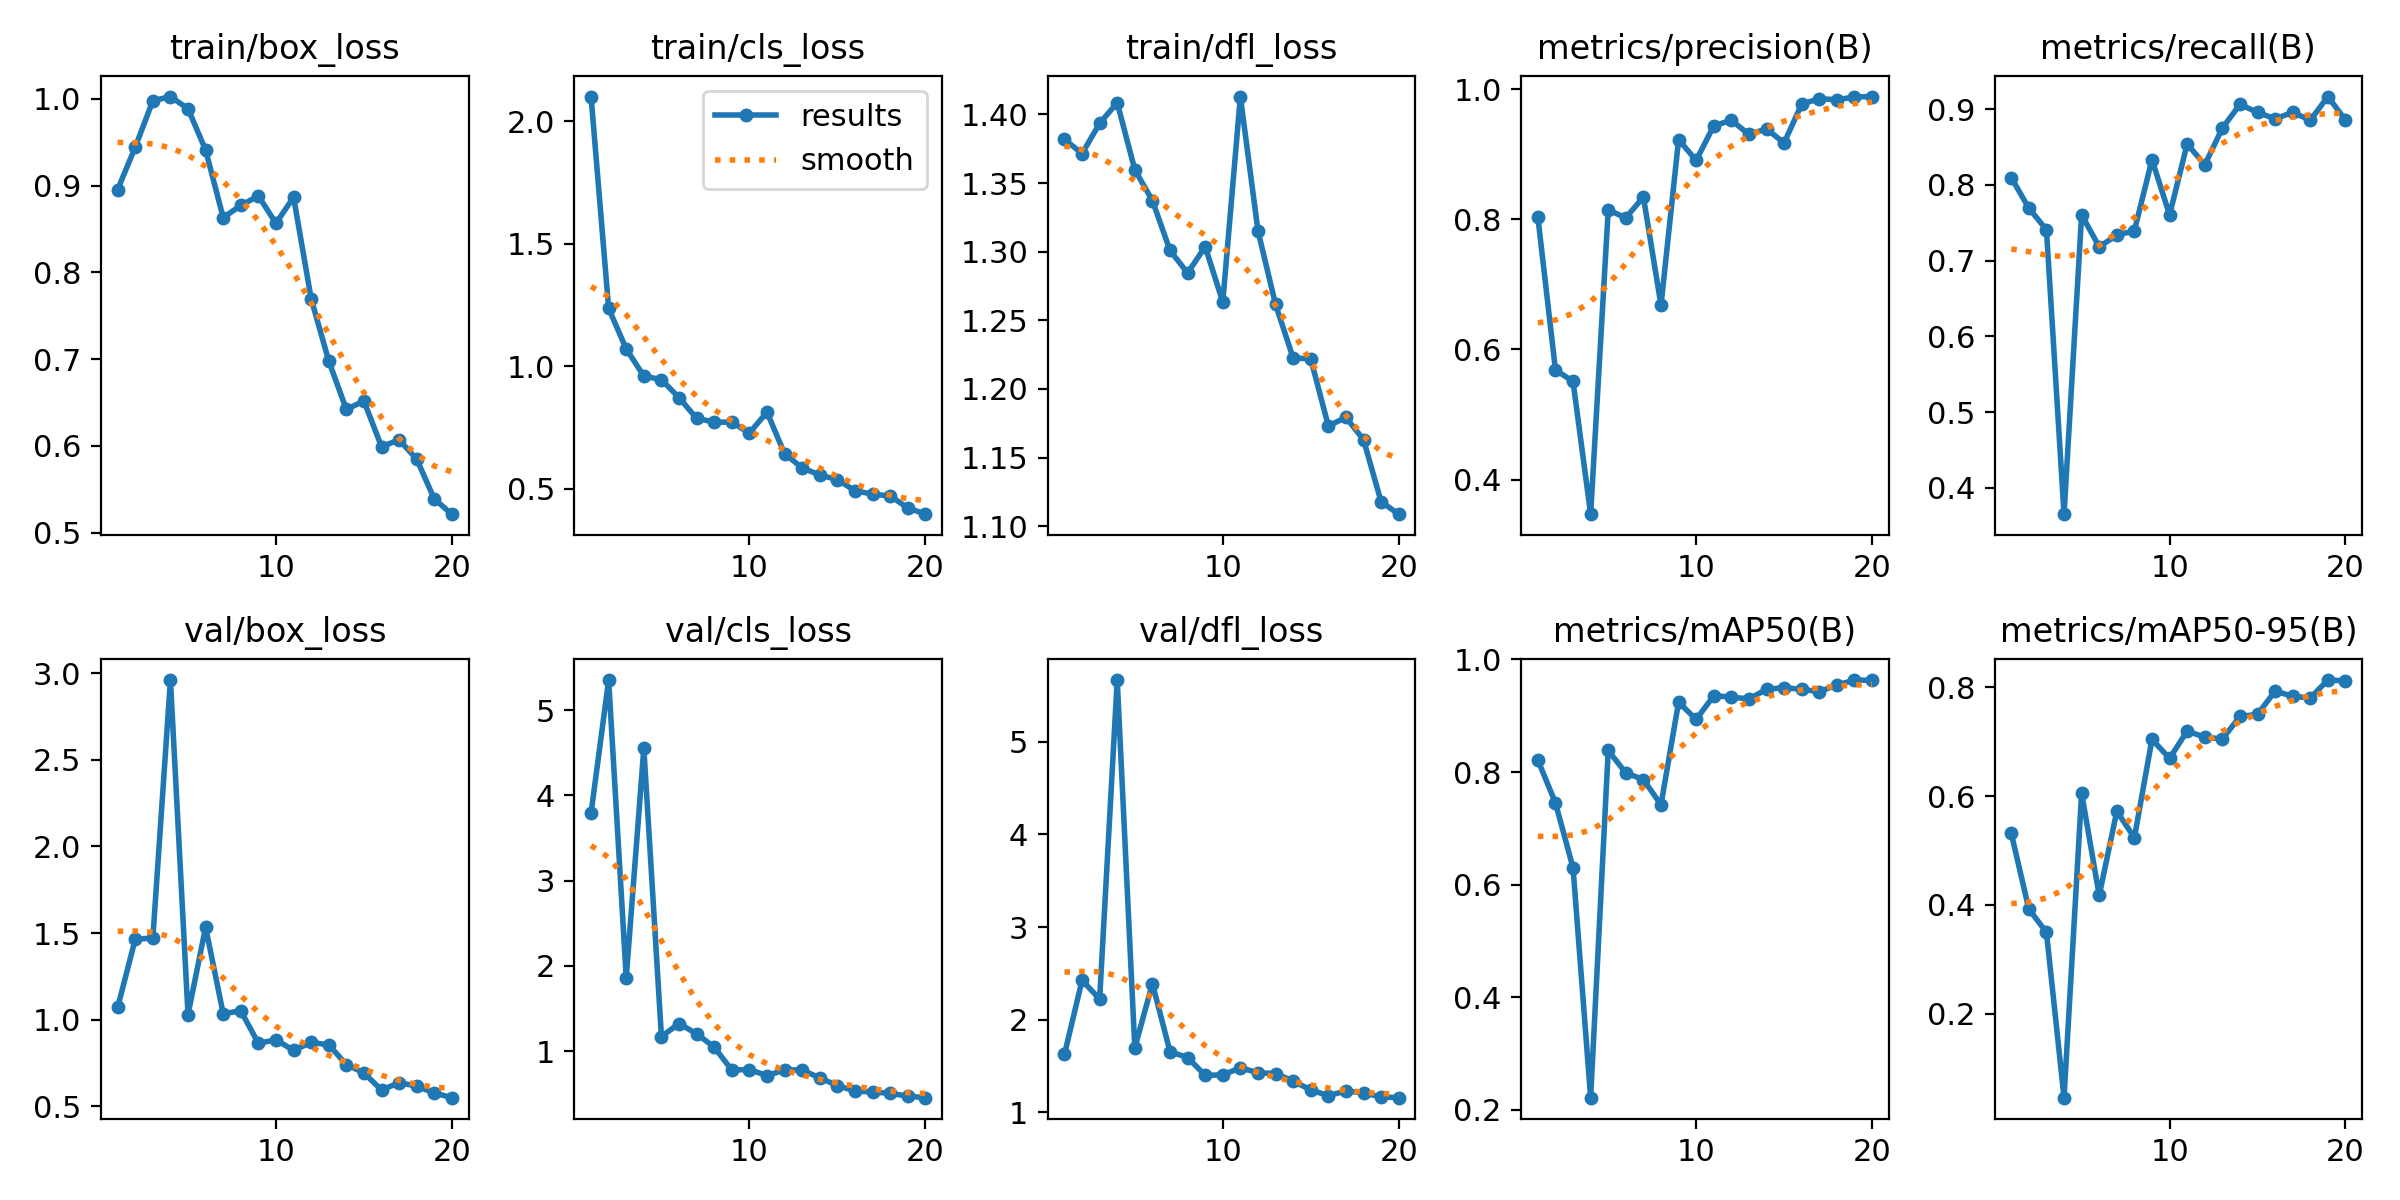

In [12]:
Image(filename = f"{resultData}results.png")

In [14]:
best_model = YOLO(
    "/content/runs/detect/helmet-detection-zktr7/helmet-detection/weights/best.pt"
)

metrics = best_model.val(
    data=data_yaml,
    split="test",
    imgsz=640
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1405.2±2254.0 MB/s, size: 253.2 KB)
val: Scanning /content/Helmet-Detection-5/test/labels... 83 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 83/83 1.8Kit/s 0.0s
val: /content/Helmet-Detection-5/test/images/images8_jpg.rf.82d69145fdd2119b3711880a955f504e.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: New cache created: /content/Helmet-Detection-5/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 48, len(boxes) = 92. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 

In [17]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

predictions = best_model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Prediction complete!")

Saving images1.jpg to images1.jpg

image 1/1 /content/images1.jpg: 640x640 1 helmet, 13.9ms
Speed: 2.2ms preprocess, 13.9ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction complete!


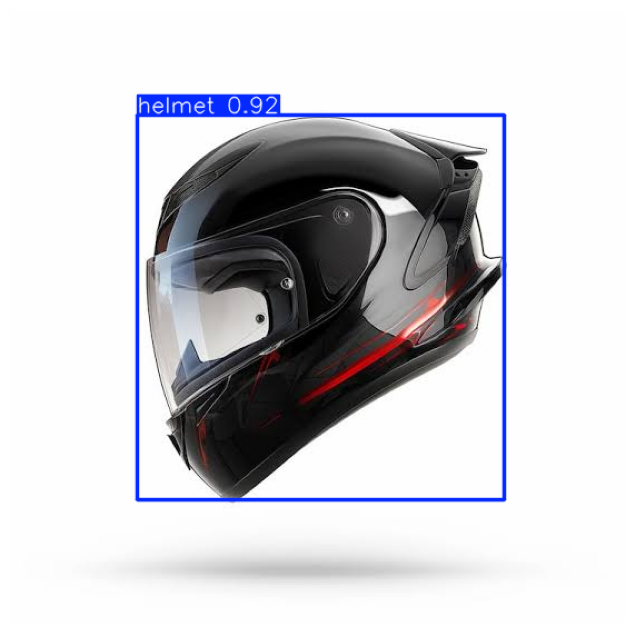

In [18]:
result_image = predictions[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(
    result_image[:, :, ::-1]
)
plt.axis("off")
plt.show()

In [19]:
import gradio as gr
from ultralytics import YOLO

# Apna trained model load karo
model = YOLO("/content/runs/detect/helmet-detection-zktr7/helmet-detection/weights/best.pt")

# Prediction function
def detect_objects(image):
    results = model.predict(image, conf=0.25)
    output_image = results[0].plot()
    return output_image

# Gradio interface
demo = gr.Interface(
    fn=detect_objects,
    inputs=gr.Image(type="pil", label="Upload Road Image"),
    outputs=gr.Image(type="numpy", label="Detection Result"),
    title="Helmet - Detection",
    description="Upload a road image  objects."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8493cd4d88010f17f4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
